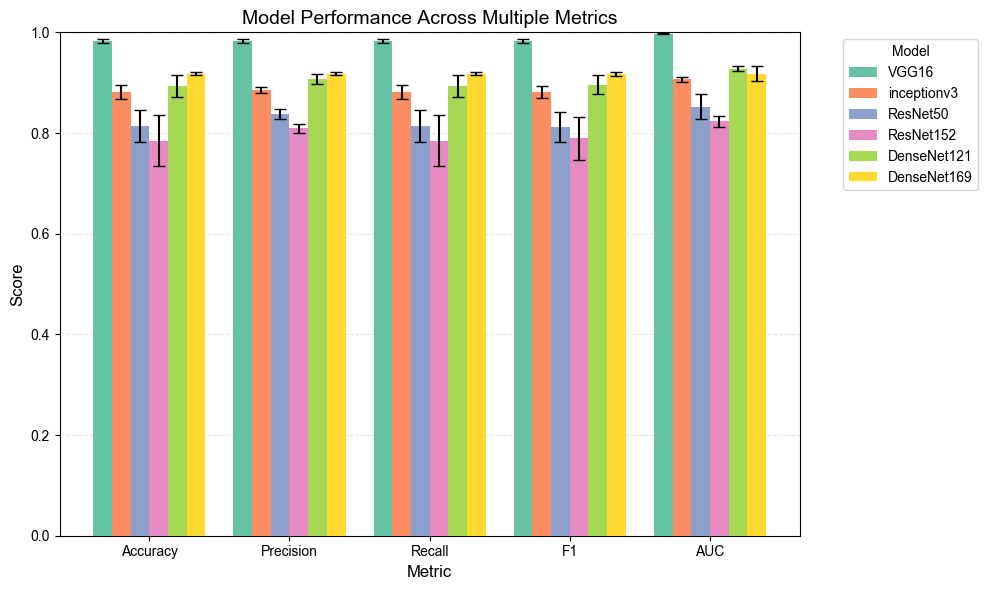

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 示例数据
data = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1", "AUC"],
    "VGG16_mean": [0.9833, 0.9836, 0.9833, 0.9833, 0.9975],
    "VGG16_std":  [0.0043, 0.0038, 0.0043, 0.0042, 0.0004],
    "ResNet50_mean": [0.8138, 0.8381, 0.8138, 0.8116, 0.8518],
    "ResNet50_std":  [0.0322, 0.0093, 0.0322, 0.0299, 0.0248],
    "ResNet152_mean": [0.7848, 0.8097, 0.7848, 0.7894, 0.8234],
    "ResNet152_std":  [0.0511, 0.0089, 0.0511, 0.0425, 0.0109],
    "inceptionv3_mean": [0.8808, 0.8859, 0.8808, 0.8817, 0.9068],
    "inceptionv3_std":  [0.0138, 0.0059, 0.0138, 0.0116, 0.0054],
    "DenseNet121_mean": [0.8930, 0.9074, 0.8930, 0.8962, 0.9280],
    "DenseNet121_std":  [0.0220, 0.0098, 0.0220, 0.0195, 0.0053],
    "DenseNet169_mean": [0.9182, 0.9178, 0.9182, 0.9170, 0.9174],
    "DenseNet169_std":  [0.0033, 0.0031, 0.0033, 0.0044, 0.0148]

}
df = pd.DataFrame(data)

# 固定顺序
metric_order = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
model_order  = ["VGG16", "inceptionv3", "ResNet50", "ResNet152", "DenseNet121", "DenseNet169"]

# 取指定顺序的数据表
df = df.set_index("Metric").loc[metric_order]

# 分组条形图手工定位
x = np.arange(len(metric_order))            # 每个指标的x位置
group_width = 0.8                           # 一组柱子的总宽度
bar_width   = group_width / len(model_order)

palette = sns.color_palette("Set2", n_colors=len(model_order))
fig, ax = plt.subplots(figsize=(10, 6))

for j, model in enumerate(model_order):
    means = df[f"{model}_mean"].values
    stds  = df[f"{model}_std"].values
    # 每个模型在一组里的位置：左移半组宽，再按列序加偏移
    pos = x - group_width/2 + bar_width/2 + j*bar_width

    # 误差线裁剪到 [0, 1]，避免越界
    upper = np.minimum(1.0, means + stds) - means
    lower = means - np.maximum(0.0, means - stds)
    yerr  = np.vstack([lower, upper])  # 非对称误差

    ax.bar(pos, means,
           width=bar_width,
           label=model,
           color=palette[j],
           edgecolor="none",
           linewidth=0.6,
           yerr=yerr,
           capsize=4,
           zorder=3)

# 坐标与样式
ax.set_xticks(x)
ax.set_xticklabels(metric_order)
ax.set_ylim(0, 1)  # 纵坐标 0~1
ax.set_ylabel("Score", fontsize=12)
ax.set_xlabel("Metric", fontsize=12)
ax.set_title("Model Performance Across Multiple Metrics", fontsize=14, weight="bold")
ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
plt.tight_layout()
plt.show()

In [5]:
import pandas as pd

# 读取 Excel 文件
df_2023 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2023-冷冻.xls")
df_2024 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2024-冷冻.xls")
df_2025 = pd.read_excel("/Users/lzz/Documents/GitHub/IVF_AI/embryo_info/23.1.1-25.7.31time-lapse原始数据新鲜+冷冻/冷冻/2025-冷冻.xls")

df_all = pd.concat([df_2023, df_2024, df_2025], ignore_index=True)

keep_cols = [
    "女病人ID",
    "ARTID",
    "年龄",
    "Bmi(新鲜周期)",
    "移植胚胎存活细胞数1",
    "移植胚胎存活细胞数2",
    "移植数",
    "妊娠结局",
    "胎儿数"
]

df_selected = df_all[[col for col in keep_cols if col in df_all.columns]]

# === 步骤 1: 仅保留 移植胚胎存活细胞数1 > 20 的行 ===
df_selected.loc[:, "移植胚胎存活细胞数1"] = (
    pd.to_numeric(df_selected["移植胚胎存活细胞数1"], errors="coerce")
    .astype("Int64")
)
df_selected = df_selected[pd.to_numeric(df_selected["移植胚胎存活细胞数1"], errors="coerce") > 20]

# === 步骤 2: 将 移植胚胎存活细胞数1 转为字符型 ===
df_selected["移植胚胎存活细胞数1"] = df_selected["移植胚胎存活细胞数1"].astype(str)

# === 步骤 3: 保留 胎儿数 == 0 或 胎儿数 == 移植数 的行 ===
df_selected["胎儿数"] = pd.to_numeric(df_selected["胎儿数"], errors="coerce")
df_selected["移植数"] = pd.to_numeric(df_selected["移植数"], errors="coerce")

df_filtered = df_selected[
    (df_selected["胎儿数"] == 0) |
    (df_selected["胎儿数"] == df_selected["移植数"])
].copy()

# === 输出结果 ===
print(df_filtered.shape)
print(df_filtered.head())

(2796, 9)
    女病人ID   ARTID    年龄  Bmi(新鲜周期) 移植胚胎存活细胞数1  移植胚胎存活细胞数2  移植数  妊娠结局  胎儿数
3  269895  216874  31.3      18.96        411         NaN    1  临床妊娠    1
4  264407  217041  24.1      21.22        423         NaN    1  临床妊娠    0
5  271697  217922  42.6      25.33        411         NaN    1  临床妊娠    0
6  266918  218241  30.4      19.05        412         NaN    1  临床妊娠    1
7  271114  218791  38.6      23.83        422         NaN    1  临床妊娠    1


In [6]:
import pandas as pd

# 确保类型正确
df_filtered["移植胚胎存活细胞数1"] = df_filtered["移植胚胎存活细胞数1"].astype(str)
df_filtered["妊娠结局"] = df_filtered["妊娠结局"].astype(str)
df_filtered = df_filtered[df_filtered["移植胚胎存活细胞数1"].str.len() >= 3].copy()

# 统计每种胚胎质量的妊娠情况
preg_stats = (
    df_filtered
    .groupby("移植胚胎存活细胞数1")
    .agg(
        总数=("妊娠结局", "count"),
        临床妊娠数=("妊娠结局", lambda x: (x == "临床妊娠").sum())
    )
    .reset_index()
)

# 计算妊娠率（百分比）
preg_stats["妊娠概率"] = preg_stats["临床妊娠数"] / preg_stats["总数"] * 100

# 排序（从高到低）
preg_stats = preg_stats.sort_values("妊娠概率", ascending=False)

# 定义转换函数
def convert_to_grade(code):
    code = str(code)
    if len(code) != 3:
        return None
    mapping = {"1": "A", "2": "B", "3": "C"}
    first = code[0]
    second = mapping.get(code[1], "?")
    third = mapping.get(code[2], "?")
    return f"{first}{second}{third}"

# 在 preg_stats 上添加囊胚等级列
preg_stats["囊胚等级"] = preg_stats["移植胚胎存活细胞数1"].apply(convert_to_grade)
preg_stats["Expansion"] = preg_stats["囊胚等级"].str[0]
preg_stats["ICM"] = preg_stats["囊胚等级"].str[1]
preg_stats["TE"] = preg_stats["囊胚等级"].str[2]

# 重新排列列顺序
preg_stats = preg_stats[
    ["囊胚等级", "Expansion", "ICM", "TE", "总数", "临床妊娠数", "妊娠概率"]
]

# 输出结果
print("各胚胎质量对应妊娠概率：")
print(preg_stats)

各胚胎质量对应妊娠概率：
   囊胚等级 Expansion ICM TE    总数  临床妊娠数        妊娠概率
15  5AA         5   A  A    12     12  100.000000
18  5BB         5   B  B     5      4   80.000000
4   3BA         3   B  A     4      3   75.000000
7   4AA         4   A  A  1007    713   70.804369
21  6AA         6   A  A    13      9   69.230769
10  4BA         4   B  A   107     74   69.158879
24  6BA         6   B  A     3      2   66.666667
8   4AB         4   A  B   431    279   64.733179
1   3AA         3   A  A    17     11   64.705882
9   4AC         4   A  C    32     18   56.250000
11  4BB         4   B  B   319    177   55.485893
2   3AB         3   A  B    57     31   54.385965
16  5AB         5   A  B     4      2   50.000000
17  5BA         5   B  A     2      1   50.000000
19  5BC         5   B  C     4      2   50.000000
5   3BB         3   B  B   140     62   44.285714
25  6BB         6   B  B     7      3   42.857143
12  4BC         4   B  C   407    172   42.260442
26  6BC         6   B  C     8      3

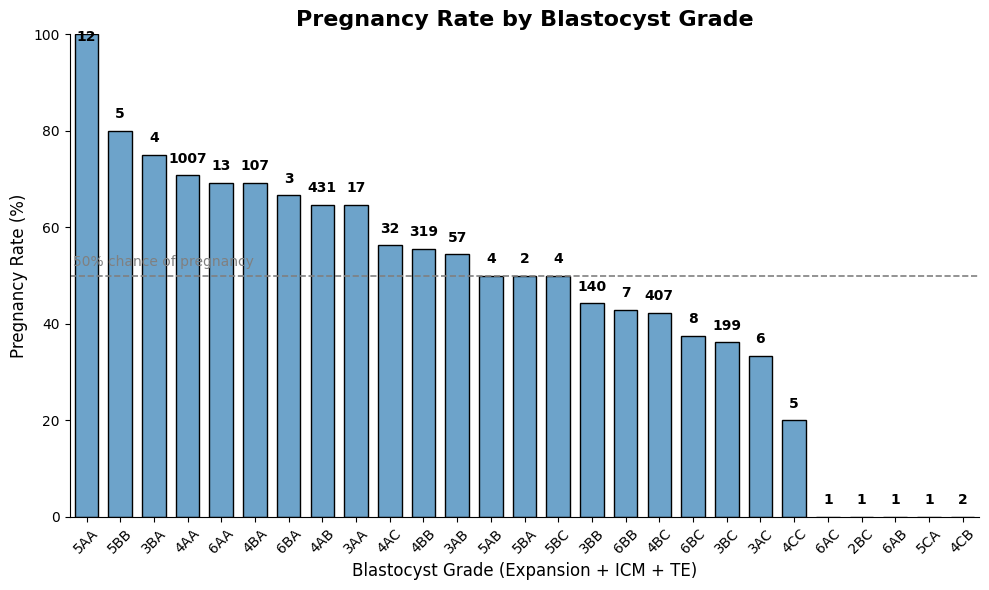

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Plot ---
fig, ax = plt.subplots(figsize=(10, 6))

bar_color = "#5DA5DA"  # 清爽蓝，可换成别的十六进制颜色

sns.barplot(
    data=preg_stats,
    x="囊胚等级",
    y="妊娠概率",
    color=bar_color,
    edgecolor="black",
    width=0.7,
    ax=ax
)

# --- Titles and labels (English) ---
ax.set_title("Pregnancy Rate by Blastocyst Grade", fontsize=16, fontweight="bold")
ax.set_xlabel("Blastocyst Grade (Expansion + ICM + TE)", fontsize=12)
ax.set_ylabel("Pregnancy Rate (%)", fontsize=12)

# --- Add a 50% reference line ---
ax.set_ylim(0, 100)
ax.axhline(50, linestyle="--", linewidth=1.2, color="gray")
ax.text(
    x=-0.4, y=52, s="50% chance of pregnancy", color="gray",
    fontsize=10
)

categories = [t.get_text() for t in ax.get_xticklabels()]
counts = (
    preg_stats.set_index("囊胚等级")
              .reindex(categories)["总数"]
              .fillna(0).astype(int)
    .tolist()
)

for patch, n in zip(ax.patches, counts):
    x = patch.get_x() + patch.get_width() / 2.0   # 柱子中心
    y = patch.get_height()                        # 柱子高度（=妊娠率）
    y_label = min(y + 2, 98)                      # 往上抬一点，且不超出顶部
    ax.text(x, y_label, n, ha="center", va="bottom",
            fontsize=10, color="black", weight="semibold")
# --- Style ---
ax.tick_params(axis="x", rotation=45)
sns.despine()
plt.tight_layout()
plt.show()

✅ 各质量类别妊娠成功率：
        Quality  Total  Pregnant  Pregnancy Rate (%)
0  Fair-quality    497       261           52.515091
1  Good-quality   1658      1137           68.576598
2  Poor-quality    640       255           39.843750


/var/folders/g0/fz4135wx06n2rb8cbgfry2lr0000gn/T/ipykernel_23603/3719840515.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


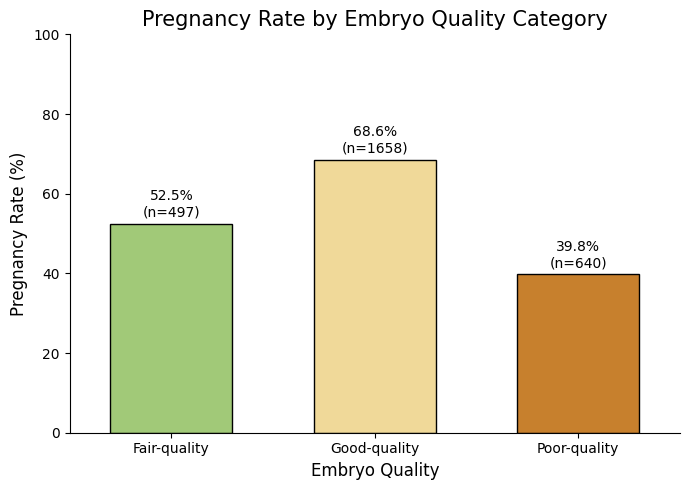

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 假设已有 preg_stats，包含列 ["囊胚等级", "总数", "临床妊娠数", "妊娠概率"]

# -------------------------------
# 1️⃣ 分类函数
# -------------------------------
def classify_quality(grade):
    grade = str(grade)
    if len(grade) < 3:
        return "Unknown"
    expansion, icm, te = grade[0], grade[1], grade[2]
    
    # Fair-quality (exact matches)
    if grade in ["3BB", "4AC", "4BB", "5BB", "4CA", "5AC", "5CA"]:
        return "Fair-quality"
    # Go-quality: extension ≥3 and (AA or AB or BA)
    elif expansion >= "3" and (
        (icm == "A" and te == "A") or 
        (icm == "A" and te == "B") or 
        (icm == "B" and te == "A") 
    ):
        return "Good-quality"
    else:
        return "Poor-quality"

# -------------------------------
# 2️⃣ 添加分类列
# -------------------------------
preg_stats["Quality"] = preg_stats["囊胚等级"].apply(classify_quality)

# -------------------------------
# 3️⃣ 按 Quality 统计妊娠率
# -------------------------------
quality_stats = (
    preg_stats
    .groupby("Quality")
    .agg(
        Total=("总数", "sum"),
        Pregnant=("临床妊娠数", "sum")
    )
    .reset_index()
)
quality_stats["Pregnancy Rate (%)"] = quality_stats["Pregnant"] / quality_stats["Total"] * 100

print("✅ 各质量类别妊娠成功率：")
print(quality_stats)

# -------------------------------
# 4️⃣ 绘图
# -------------------------------
fig, ax = plt.subplots(figsize=(7, 5))

palette = ["#A1D76A", "#FEE08B", "#E08214"]  # Green→Yellow→Orange 渐变
sns.barplot(
    data=quality_stats,
    x="Quality",
    y="Pregnancy Rate (%)",
    palette=palette,
    edgecolor="black",
    width=0.6,
    ax=ax
)

# 添加数值标签（样本量）
for i, row in quality_stats.iterrows():
    ax.text(i, row["Pregnancy Rate (%)"] + 1, 
            f"{row['Pregnancy Rate (%)']:.1f}%\n(n={int(row['Total'])})",
            ha="center", va="bottom", fontsize=10)

# -------------------------------
# 5️⃣ 美化
# -------------------------------
ax.set_title("Pregnancy Rate by Embryo Quality Category", fontsize=15)
ax.set_xlabel("Embryo Quality", fontsize=12)
ax.set_ylabel("Pregnancy Rate (%)", fontsize=12)
ax.set_ylim(0, 100)

sns.despine()
plt.tight_layout()
plt.show()

✅ 各年龄段统计：
     年龄段    人数        百分比
0  18-24    91   2.091473
1  25-29   937  21.535279
2  30-34  1742  40.036773
3  35-39  1063  24.431165
4  40-44   455  10.457366
5    ≥45    63   1.447943


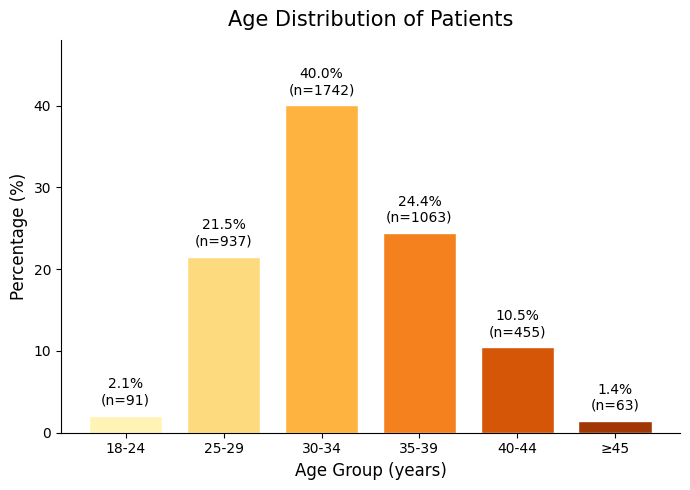

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ==============================
# 1️⃣ 读取与清洗数据
# ==============================
df_age = pd.read_csv("/Users/lzz/Documents/GitHub/IVF_AI/SlidePatientBirthDates.csv")

df_age["Age"] = pd.to_numeric(df_age["Age"], errors="coerce")
df_age = df_age[df_age["Age"].notna() & (df_age["Age"] >= 18) & (df_age["Age"] <= 100)].copy()

# ==============================
# 2️⃣ 按年龄区间分组
# ==============================
bins = [18, 25, 30, 35, 40, 45, 100]
labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "≥45"]
df_age["年龄段"] = pd.cut(df_age["Age"], bins=bins, labels=labels, right=False)

# ==============================
# 3️⃣ 统计每个年龄段的数量与百分比
# ==============================
age_stats = (
    df_age["年龄段"]
    .value_counts()
    .sort_index()
    .reset_index()
)
age_stats.columns = ["年龄段", "人数"]
age_stats["百分比"] = age_stats["人数"] / age_stats["人数"].sum() * 100

print("✅ 各年龄段统计：")
print(age_stats)

# ==============================
# 4️⃣ 设置配色
# ==============================
colors = sns.color_palette("YlOrBr", n_colors=len(age_stats))

# ==============================
# 5️⃣ 绘图
# ==============================
plt.figure(figsize=(7, 5))
bars = plt.bar(
    age_stats["年龄段"],
    age_stats["百分比"],
    color=colors,
    edgecolor="white",
    width=0.75
)

# ==============================
# 6️⃣ 美化图形
# ==============================
plt.title("Age Distribution of Patients", fontsize=15, pad=10)
plt.xlabel("Age Group (years)", fontsize=12)
plt.ylabel("Percentage (%)", fontsize=12)
plt.ylim(0, age_stats["百分比"].max() * 1.2)

# 添加百分比与人数标签
for i, row in age_stats.iterrows():
    plt.text(
        i, row["百分比"] + 1,
        f"{row['百分比']:.1f}%\n(n={row['人数']})",
        ha='center', va='bottom', fontsize=10
    )

sns.despine()
plt.tight_layout()
plt.show()

✅ 各年龄段妊娠率：
     年龄段    总数  临床妊娠数     妊娠率(%)
0  18-24    75     51  68.000000
1  25-29   700    479  68.428571
2  30-34  1149    730  63.533507
3  35-39   634    333  52.523659
4  40-44   229     59  25.764192
5   >=45     8      1  12.500000


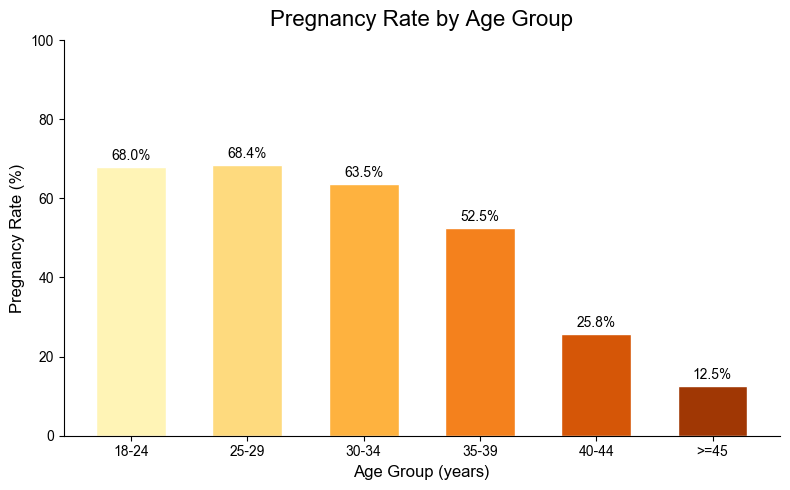

In [45]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# ==============================
# 1️⃣ 数据准备
# ==============================
df_filtered["年龄"] = pd.to_numeric(df_filtered["年龄"], errors="coerce")
df_filtered["妊娠结局"] = df_filtered["妊娠结局"].astype(str)

# 年龄区间
bins = [18, 25, 30, 35, 40, 45, 100]
labels = ["18-24", "25-29", "30-34", "35-39", "40-44", ">=45"]
df_filtered["年龄段"] = pd.cut(df_filtered["年龄"], bins=bins, labels=labels, right=False)

# 各年龄段妊娠率
age_stats = (
    df_filtered
    .groupby("年龄段")
    .agg(
        总数=("妊娠结局", "count"),
        临床妊娠数=("妊娠结局", lambda x: (x == "临床妊娠").sum())
    )
    .reset_index()
)
age_stats["妊娠率(%)"] = age_stats["临床妊娠数"] / age_stats["总数"] * 100

print("✅ 各年龄段妊娠率：")
print(age_stats)

# ==============================
# 2️⃣ 自定义渐变配色（黄色→橙色）
# ==============================
colors = sns.color_palette("YlOrBr", n_colors=len(age_stats))  # 黄色到橙棕色渐变
# 或者更亮：sns.color_palette("YlOrRd", n_colors=len(age_stats))

# ==============================
# 3️⃣ 绘图
# ==============================
plt.figure(figsize=(8, 5))

bars = plt.bar(
    age_stats["年龄段"],
    age_stats["妊娠率(%)"],
    color=colors,
    edgecolor="white",
    width=0.6
)

# ==============================
# 4️⃣ 美化
# ==============================
plt.title("Pregnancy Rate by Age Group", fontsize=16, weight="bold", pad=10)
plt.xlabel("Age Group (years)", fontsize=12, weight="bold")
plt.ylabel("Pregnancy Rate (%)", fontsize=12, weight="bold")
plt.ylim(0, 100)

# 添加柱顶数值
for i, row in age_stats.iterrows():
    plt.text(i, row["妊娠率(%)"] + 1, f"{row['妊娠率(%)']:.1f}%", 
             ha='center', va='bottom', fontsize=10, weight="semibold")

# 优化外观
sns.despine()
plt.tight_layout()
plt.show()